# Topic 23b - Simple regression

The main lesson fit one regression line (quantity vs. revenue, R² = 0.17) and called it usable but not strong. This notebook covers reading R² and residuals properly, and a second example where the fit is much weaker - so you learn to judge a fit, not just produce one.

Work through it after reading section "What's new: simple regression" of the [main lesson](topic23_capstone_project.ipynb).

In [1]:
# Run this cell as it is.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_data_dir():
    """Locate the lesson's data folder from the repository root, the lesson
    folder, or the assignments folder, so this notebook runs from anywhere."""
    candidates = [
        Path.cwd() / "data",
        Path.cwd() / "capstone_project" / "data",
        Path.cwd().parent / "data",
    ]
    for candidate in candidates:
        if (candidate / "orders.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find orders.csv. Looked in: " + ", ".join(str(c) for c in candidates)
    )


DATA_DIR = find_data_dir()

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 130)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e1e0d9"
plt.rcParams["grid.linewidth"] = 0.8
plt.rcParams["axes.edgecolor"] = "#c3c2b7"
plt.rcParams["axes.axisbelow"] = True

PALETTE = {
    "blue": "#2a78d6", "aqua": "#1baf7a", "yellow": "#eda100", "green": "#008300",
    "violet": "#4a3aa7", "red": "#e34948", "magenta": "#e87ba4", "orange": "#eb6834",
}
MUTED = "#c3c2b7"
INK = "#0b0b0b"

print("pandas version:   ", pd.__version__)
print("data folder:      ", DATA_DIR)
print("files:            ", sorted(p.name for p in DATA_DIR.glob("*.csv")))

pandas version:    3.0.6
data folder:       /home/johnny/Projects/itfy-da/capstone_project/data
files:             ['air_quality_readings.csv', 'air_quality_stations.csv', 'customers.csv', 'monthly_targets_wide.csv', 'orders.csv', 'products.csv', 'regions.csv', 'returns.csv']


In [2]:
# The retail "2023 Trading Review" table from Topic 20, reused throughout
# this topic exactly as Topic 22 reused it for the two report types.
def clean_region(series):
    return (series.str.strip().str.replace(r"\s+", " ", regex=True).str.title())


def build_analysis_table(orders, customers, products, regions, returns):
    expected_rows = len(orders)
    customers = customers.copy()
    customers["region"] = clean_region(customers["region"])
    products = products.drop_duplicates(subset="product_id", keep="first")
    customers = customers.merge(regions, on="region", how="left", validate="m:1")
    table = (orders
             .merge(customers, on="customer_id", how="left", validate="m:1")
             .merge(products, on="product_id", how="left", validate="m:1"))
    returned_ids = set(returns["order_id"])
    table["was_returned"] = table["order_id"].isin(returned_ids)
    table["order_date"] = pd.to_datetime(table["order_date"])
    table["month"] = table["order_date"].dt.strftime("%b")
    table["revenue_ghs"] = (table["quantity"] * table["unit_price_ghs"]).round(2)
    table["cost_ghs"] = (table["quantity"] * table["unit_cost_ghs"]).round(2)
    table["profit_ghs"] = (table["revenue_ghs"] - table["cost_ghs"]).round(2)
    if len(table) != expected_rows:
        raise ValueError("Row count changed during wrangling.")
    return table.sort_values("order_date").reset_index(drop=True)


orders = pd.read_csv(DATA_DIR / "orders.csv")
customers = pd.read_csv(DATA_DIR / "customers.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
regions = pd.read_csv(DATA_DIR / "regions.csv")
returns = pd.read_csv(DATA_DIR / "returns.csv")

analysis = build_analysis_table(orders, customers, products, regions, returns)
print(f"Retail analysis table: {analysis.shape[0]} rows x {analysis.shape[1]} columns")

Retail analysis table: 1200 rows x 23 columns


In [3]:
aq_stations = pd.read_csv(DATA_DIR / "air_quality_stations.csv")
aq_readings = pd.read_csv(DATA_DIR / "air_quality_readings.csv", parse_dates=["date"])
aq = aq_readings.merge(aq_stations, on="station_id", how="left", validate="m:1")
print(f"Air-quality table: {aq.shape[0]} rows")

Air-quality table: 3285 rows


---

## Fitting a line: slope, intercept, and what they mean

`np.polyfit(x, y, 1)` returns the slope and intercept of the best-fit line through `(x, y)` - "best" meaning it minimises the sum of squared vertical distances from each point to the line (least squares).

In [4]:
x = analysis["quantity"].values.astype(float)
y = analysis["revenue_ghs"].values

slope, intercept = np.polyfit(x, y, 1)
print(f"revenue_ghs = {slope:.2f} x quantity + {intercept:.2f}")
print(f"Interpretation: each additional unit ordered is associated with about GHS {slope:.2f} more revenue,")
print(f"and an order of zero quantity (meaningless here, but the maths still gives it a value) predicts GHS {intercept:.2f}.")

revenue_ghs = 39.67 x quantity + 17.33
Interpretation: each additional unit ordered is associated with about GHS 39.67 more revenue,
and an order of zero quantity (meaningless here, but the maths still gives it a value) predicts GHS 17.33.


That last line matters: the intercept is whatever the equation says at x = 0, whether or not x = 0 makes sense for your data. An order of zero quantity cannot exist, so the intercept here is a mathematical artefact, not a real prediction - always check whether x = 0 is a meaningful point before interpreting the intercept as a fact about the world.

---

## R²: how much the line actually explains

R² compares the line's errors to the simplest possible guess - always predicting the mean. R² = 1 means the line explains all the variation; R² = 0 means it explains none, no better than guessing the average every time.

In [5]:
def fit_and_r_squared(x, y):
    slope, intercept = np.polyfit(x, y, 1)
    predicted = slope * x + intercept
    ss_res = ((y - predicted) ** 2).sum()
    ss_tot = ((y - y.mean()) ** 2).sum()
    r_squared = 1 - ss_res / ss_tot
    return slope, intercept, r_squared, predicted


slope, intercept, r2, predicted = fit_and_r_squared(x, y)
print(f"quantity -> revenue: R\u00b2 = {r2:.3f}")
print(f"In plain terms: quantity explains about {r2*100:.0f}% of why one order's revenue differs from another's.")
print(f"The other {(1 - r2) * 100:.0f}% comes from unit price and everything else this line does not use.")

quantity -> revenue: R² = 0.172
In plain terms: quantity explains about 17% of why one order's revenue differs from another's.
The other 83% comes from unit price and everything else this line does not use.


---

## A much weaker fit: temperature and PM2.5

A line can always be fitted - `polyfit` never refuses. Whether the result is worth reporting is a separate question, answered by R², not by whether the function ran without error.

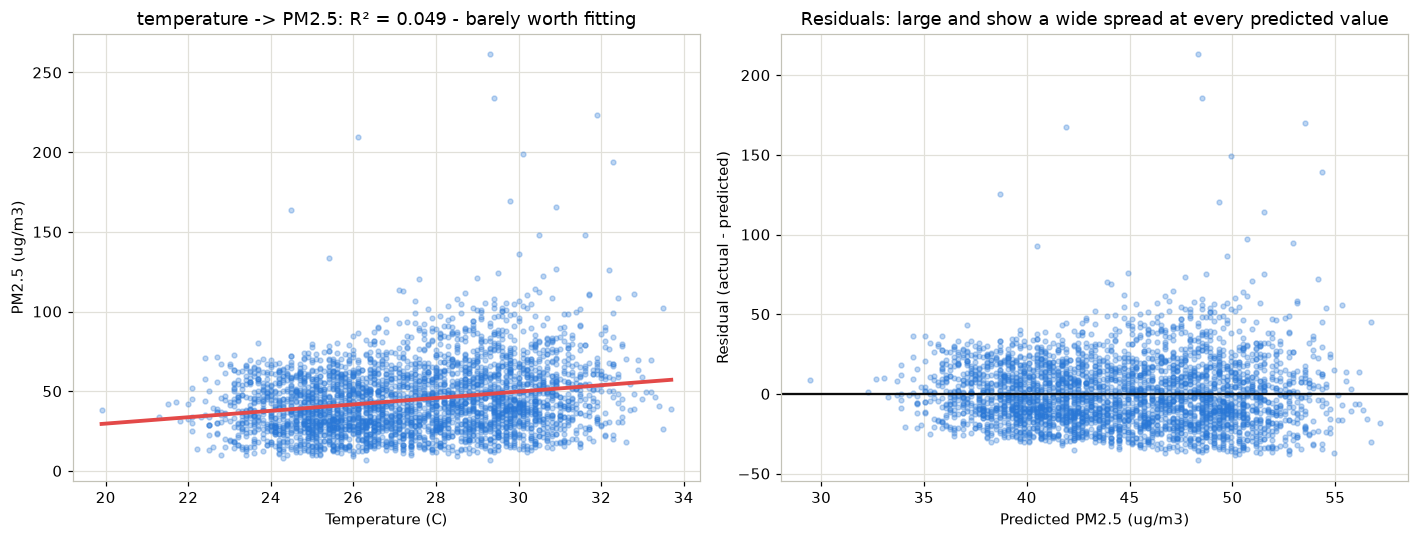

R² = 0.049: temperature explains about 5% of PM2.5's variation - not nothing, but not a
relationship to build a claim on by itself.


In [6]:
x2 = aq["temperature_c"].dropna().values
y2 = aq.loc[aq["temperature_c"].notna(), "pm2_5"]
mask = y2.notna()
x2, y2 = x2[mask.values], y2[mask].values

slope2, intercept2, r2_2, predicted2 = fit_and_r_squared(x2, y2)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(x2, y2, s=10, alpha=0.3, color=PALETTE["blue"])
x_line = np.linspace(x2.min(), x2.max(), 50)
axes[0].plot(x_line, slope2 * x_line + intercept2, color=PALETTE["red"], linewidth=2.5)
axes[0].set_title(f"temperature -> PM2.5: R\u00b2 = {r2_2:.3f} - barely worth fitting")
axes[0].set_xlabel("Temperature (C)")
axes[0].set_ylabel("PM2.5 (ug/m3)")

residuals = y2 - predicted2
axes[1].scatter(predicted2, residuals, s=10, alpha=0.3, color=PALETTE["blue"])
axes[1].axhline(0, color=INK, linewidth=1.5)
axes[1].set_title("Residuals: large and show a wide spread at every predicted value")
axes[1].set_xlabel("Predicted PM2.5 (ug/m3)")
axes[1].set_ylabel("Residual (actual - predicted)")

fig.tight_layout()
plt.show()

print(f"R\u00b2 = {r2_2:.3f}: temperature explains about {r2_2*100:.0f}% of PM2.5's variation - not nothing, but not a")
print("relationship to build a claim on by itself.")

The residual plot on the right is doing real work: a good fit has residuals scattered evenly around zero with no pattern. Here they are not just scattered - they are *large* relative to the predictions, which is the visual version of a low R². If the residuals instead curved or fanned out as predictions grew, that would be a sign the relationship is not linear at all, which `polyfit` cannot tell you - it only ever fits a straight line, whether or not a straight line is the right shape.

This also connects straight back to Topic 22: temperature correlates with PM2.5 at r = 0.22 - both numbers are reporting the same weak relationship, and the reason is the same one from Topic 22's correlation-vs-shared-cause section. Temperature does not control air quality directly; both temperature and PM2.5 happen to follow the dry season. A regression line here is dressing up a confound in an equation, not describing a real cause.

### Try It 2 - fit and judge, don't just fit

Fit a regression of `wind_speed_kmh` predicting `pm2_5`. Report the slope, intercept, and R², and write one sentence saying whether you would use this line to make a real prediction, and why.

In [7]:
# YOUR CODE HERE

---
## Where this fits

- [Back to the main lesson](topic23_capstone_project.ipynb)
- Previous: [23a - SQL basics](topic23a_sql_basics.ipynb)
- Next: [23c - Choosing your dataset](topic23c_choosing_your_dataset.ipynb)